# Nuclear Water & Climate Lab — saved-results review

**No training runs in this notebook.** It reads original local inputs and previously saved MODEL results, independently checks each export and recalculates MAE. The original training code is in `src/model/`; the legacy Surry training notebook is unchanged and has no saved outputs. These visible outputs were produced by a local artifact-review execution, **not by training in Colab**.

Track: AI + Climate. Team: **[FILL IN BOTH PARTICIPANTS]**.

Target: retrospective monthly cooling-system ΔT = discharge minus intake (°C). Intake is known after the month; this is not an advance forecast or a safety assessment. No significance claim or worldwide coverage claim is made.

Local: open inside the extracted release. Colab: upload this notebook, Run all, then upload `nuclear-water-release.zip` when asked. The release inputs stay local to the runtime. CPU is sufficient. Required: pandas, numpy, pyarrow, matplotlib (UI dependencies are pinned in `src/ui/requirements.txt`; Colab normally has the plotting packages).


## Imports

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

## Locate the local bundle or upload the release ZIP once in Colab

In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "data/model_artifacts/multistation/registry.json").is_file()), None)
if ROOT is None:
    from google.colab import files
    from zipfile import ZipFile
    from io import BytesIO
    import stat
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one nuclear-water-release.zip")
    ROOT = Path("nuclear-water-release").resolve()
    ROOT.mkdir(exist_ok=False)
    with ZipFile(BytesIO(next(iter(uploaded.values())))) as archive:
        destinations = []
        for item in archive.infolist():
            target = (ROOT / item.filename).resolve()
            if not target.is_relative_to(ROOT) or "\\" in item.filename or ":" in item.filename or stat.S_ISLNK(item.external_attr >> 16):
                raise ValueError("Unsafe release archive path")
            if target in destinations:
                raise ValueError("Duplicate release archive path")
            destinations.append(target)
        archive.extractall(ROOT)
print("Input bundle located. Original inputs and model artifacts will only be read.")

Input bundle located. Original inputs and model artifacts will only be read.


## Read the registry through the existing reader

In [3]:
sys.path.insert(0, str(ROOT / "src/ui"))
from multistation_loader import registry_snapshot, measurements_snapshot, verified_results
registry, token = registry_snapshot(ROOT)
entries = registry["datasets"]
print("Registry systems:", len(entries), "| EIA plant IDs:", len({e["plant_id_eia"] for e in entries}))
print("Data states:", dict(Counter(e["status"] for e in entries)))
print("No training: existing MODEL adapter and read-only export verifier only.")

Registry systems: 102 | EIA plant IDs: 66
Data states: {'review_required': 41, 'measurements_only': 21, 'reference_only': 8, 'blocked': 15, 'ready_for_model_check': 17}
No training: existing MODEL adapter and read-only export verifier only.


## Independently verify all saved system results

In [4]:
rows = []
checked = {}
for entry in entries:
    if entry["status"] != "ready_for_model_check" or entry["model_status"] not in {"existing_verified", "evaluated_verified"}:
        continue
    measurements, audit = measurements_snapshot(entry, token, ROOT)
    results, scores = verified_results(entry, measurements, token, ROOT)
    beats = scores["model_delta_t_c"] < min(scores["median_baseline_delta_t_c"], scores["seasonal_baseline_delta_t_c"])
    rows.append({"dataset_id": entry["dataset_id"], "Plant": entry["plant_name"], "System": entry["cooling_id_eia"], "Train": entry["split_counts"]["train"], "Validation": entry["split_counts"]["validation"], "Test": len(results), "Ridge MAE (C)": scores["model_delta_t_c"], "Overall median MAE (C)": scores["median_baseline_delta_t_c"], "Seasonal median MAE (C)": scores["seasonal_baseline_delta_t_c"], "Beats best baseline": beats})
    checked[(entry["plant_id_eia"], entry["cooling_id_eia"])] = results
summary = pd.DataFrame(rows)
assert len(summary) == 17 and int(summary["Beats best baseline"].sum()) == 4, "Release results differ; investigate before submitting"
display(summary)
print("17 systems evaluated; Ridge improves on the best baseline in 4, and is worse in 13. No models were reselected.")

,dataset_id,Plant,System,Train,Validation,Test,Ridge MAE (C),Overall median MAE (C),Seasonal median MAE (C),Beats best baseline
0,eia_880_504c414e54,Quad Cities Generating Station,PLANT,144,24,24,1.361909,3.287037,1.111111,False
1,eia_2410_4e535332,PSEG Salem Generating Station,NSS2,132,24,24,1.179570,1.064815,1.064815,False
2,eia_2589_5531,Nine Mile Point Nuclear Station,U1,132,24,24,1.149599,1.157407,1.157407,True
3,eia_3166_504c414e54,Peach Bottom,PLANT,144,24,24,1.017679,1.319444,0.879630,False
4,eia_3265_31434357,Oconee,1CCW,144,24,24,0.703784,0.995371,0.995370,True
5,eia_3806_435731,Surry,CW1,142,24,22,1.849330,1.994950,2.045454,True
6,eia_4046_4357,Point Beach Nuclear Plant,CW,144,24,24,1.505864,1.921296,0.902777,False
7,eia_4046_435732,Point Beach Nuclear Plant,CW2,108,24,24,2.020413,3.194445,1.342593,False
8,eia_6000_554e495431,Donald C Cook,UNIT1,70,24,12,1.061511,1.111111,1.087963,True
9,eia_6000_554e495432,Donald C Cook,UNIT2,68,24,12,1.383337,1.574075,1.250000,False


17 systems evaluated; Ridge improves on the best baseline in 4, and is worse in 13. No models were reselected.


## A real error and the saved Surry test comparison

,reported_delta_t_c,model_delta_t_c,absolute_error_c
report_month,,,
2025-12,6.666667,11.028858,4.362191


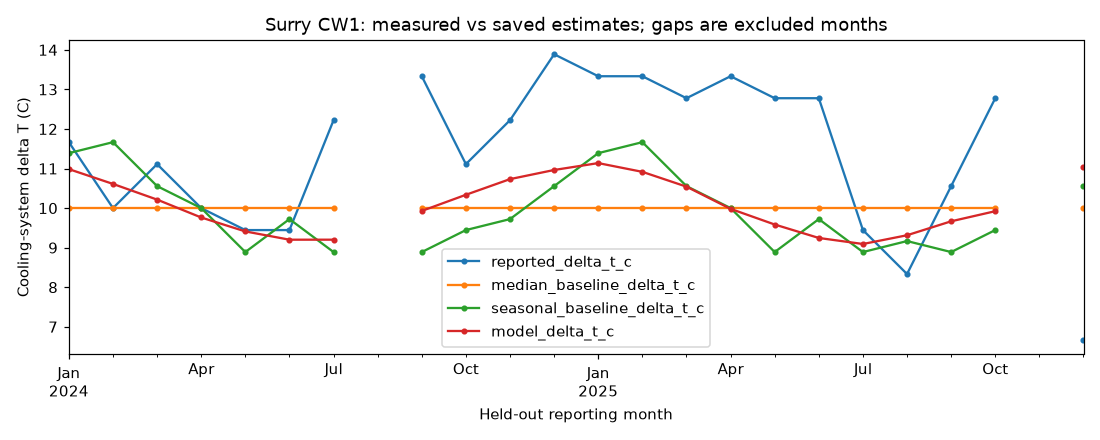

2025-12 is a real error example, not evidence about ecosystem harm or safety.


In [5]:
surry = checked[(3806, "CW1")]
example = surry.loc[["2025-12"], ["reported_delta_t_c", "model_delta_t_c"]].copy()
example["absolute_error_c"] = (example.model_delta_t_c - example.reported_delta_t_c).abs()
display(example)
figure, axes = plt.subplots(figsize=(10, 4))
plot = surry[["reported_delta_t_c", "median_baseline_delta_t_c", "seasonal_baseline_delta_t_c", "model_delta_t_c"]].copy()
plot.index = pd.to_datetime(plot.index)
plot = plot.reindex(pd.date_range(plot.index.min(), plot.index.max(), freq="MS"))
plot.plot(ax=axes, marker=".")
axes.set(xlabel="Held-out reporting month", ylabel="Cooling-system delta T (C)", title="Surry CW1: measured vs saved estimates; gaps are excluded months")
figure.tight_layout()
display(figure)
plt.close(figure)
print("2025-12 is a real error example, not evidence about ecosystem harm or safety.")

## Snapshot consistency and interpretation

In [6]:
assert hashlib.sha256((ROOT / "data/model_artifacts/multistation/registry.json").read_bytes()).hexdigest() == token
print("Registry snapshot remained unchanged. Review completed without training or overwriting MODEL files.")
print("Original model choices: fixed Ridge alpha grid 0.1, 1, 10, 100; train 2010–2021; validation 2022–2023; test 2024–2025.")
print("Features: same-month intake temperature and calendar sine/cosine. Discharge and current target are excluded from predictors.")

Registry snapshot remained unchanged. Review completed without training or overwriting MODEL files.
Original model choices: fixed Ridge alpha grid 0.1, 1, 10, 100; train 2010–2021; validation 2022–2023; test 2024–2025.
Features: same-month intake temperature and calendar sine/cosine. Discharge and current target are excluded from predictors.
